# Provenance classifier baseline: real survey cutout vs GMM sky field

Notebook version of `misc/provenance_classifier_baseline.py`, for poking at the
result.  Same features, same model, same CV; the `.py` stays as the one-shot
command-line version cited in the paper draft.

**Question.** The LMMs are asked "What is the underlying distribution used to
create the data in this figure? [gaussian mixture model, real image of the
sky]" and answer "real" almost regardless of the truth.  Is that question
answerable from image content at all?  A gradient-boosted classifier on four
low-level features says how separable the two families are.

**Features** (one row per sky figure, from the stored data array
`plot0.data.colors` and the figure's own ground-truth answers):

| feature | definition |
|---|---|
| field size | log10 sqrt(field width × field height), arcmin.  GMM fields are drawn to the same angular-size distribution, so this should be near chance -- a check on the matching. |
| concentration | fraction of the background-subtracted signal (background = data minimum) in the brightest `top_frac` of pixels |
| colour span | log10(max − min) of the data -- the dynamic range behind the colorbar |
| colour min sign | sign of the data minimum (−1, 0, +1) |

Sections: config → features (cached to CSV) → what the features look like →
CV and the **accuracy table** → where it goes wrong.

In [1]:
# ======================== CONFIG ========================
qa_dir    = '~/astro_sky_image_vqa/VQA_full/qa_jsons/'
# run pickles naming the figures the LMMs were evaluated on (n255 run)
eval_dir  = '~/astro_sky_image_vqa/LMM_outputs_n255/gemini/'

top_frac  = 0.05     # brightest-pixel fraction used for `concentration`
folds     = 5
seed      = 0

# Reading the 1334 sky qa_jsons takes about a minute, so the feature table is
# cached here.  Set recompute = True after changing a feature definition or
# top_frac -- the cache does not know about either.
features_csv = 'provenance_features.csv'
recompute    = False

FEATURES = ['field size', 'concentration', 'colour span', 'colour min sign']

In [2]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix


def _answers(rec):
    """Flatten every ground-truth answer in a qa json into {name: value}."""
    out = {}
    for lvl in rec['VQA'].values():
        for items in lvl.values():
            for name, e in items.items():
                # plot-level questions nest one level deeper, under 'plot0'
                entry = e if 'A' in e else e.get('plot0', {})
                a = entry.get('A')
                if isinstance(a, dict) and name in a:
                    out[name] = a[name]
    return out


def figure_features(rec, top_frac):
    """The four features for one sky figure, or None if it is not a sky panel."""
    p = rec['plot0']
    if p['type'] != 'image of the sky':
        return None
    data = np.asarray(p['data']['colors'], dtype=float)
    data = data[np.isfinite(data)]
    dmin, dmax = data.min(), data.max()

    signal = np.sort(data - dmin)[::-1]
    ntop = max(1, int(round(top_frac * signal.size)))
    total = signal.sum()
    concentration = signal[:ntop].sum() / total if total > 0 else 0.0

    ans = _answers(rec)
    width, height = float(ans['field width']), float(ans['field height'])

    return {
        'vqa_id': rec['vqa_id'],
        'label': 'gmm' if p.get('distribution') == 'gmm' else 'real',
        'field size': np.log10(np.sqrt(width * height)),
        'concentration': concentration,
        'colour span': np.log10(dmax - dmin) if dmax > dmin else -12.0,
        'colour min sign': float(np.sign(dmin)),
    }

## Features

In [3]:
if os.path.exists(features_csv) and not recompute:
    df = pd.read_csv(features_csv)
    print('read cached features from', features_csv)
else:
    rows = []
    for fp in sorted(glob.glob(os.path.join(os.path.expanduser(qa_dir), '*_qa.json'))):
        with open(fp) as f:
            rec = json.loads(json.load(f))
        r = figure_features(rec, top_frac)
        if r is not None:
            rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(features_csv, index=False)
    print('computed features, wrote', features_csv)

evaluated = {os.path.basename(p).removesuffix('_qa.pickle')
             for p in glob.glob(os.path.join(os.path.expanduser(eval_dir), '*_qa.pickle'))}
df['lmm_evaluated'] = df['vqa_id'].isin(evaluated)

print('sky figures: %d  (real %d, gmm %d); %d in the LMM evaluation'
      % (len(df), (df.label == 'real').sum(), (df.label == 'gmm').sum(), df.lmm_evaluated.sum()))
df.head()

read cached features from provenance_features.csv
sky figures: 1334  (real 667, gmm 667); 170 in the LMM evaluation


,vqa_id,label,field size,concentration,colour span,colour min sign,lmm_evaluated
0,vqa_000001,gmm,1.937102,0.105647,2.332720,1.0,True
1,vqa_000002,real,0.235253,0.317722,4.297340,1.0,True
2,vqa_000003,real,0.227105,0.304252,4.208726,1.0,True
3,vqa_000004,real,-0.051603,0.232582,4.124883,1.0,True
4,vqa_000005,real,2.042715,0.185151,2.362434,1.0,True


### What the features look like

Medians by family, then one histogram per feature.  A feature whose two
histograms overlap is one the matching neutralised; one where they separate is
what gives the GMM fields away.

label,gmm,real
field size,1.710,1.524
concentration,0.085,0.196
colour span,2.407,2.407
colour min sign,1.000,1.000


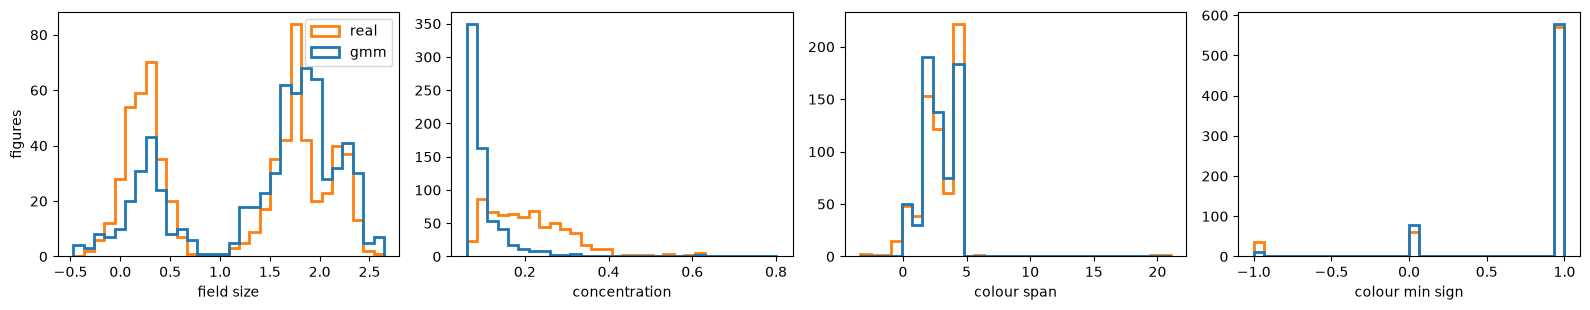

In [4]:
display(df.groupby('label')[FEATURES].median().T.round(3))

fig, axes = plt.subplots(1, len(FEATURES), figsize=(4 * len(FEATURES), 3.2))
for ax, f in zip(axes, FEATURES):
    bins = np.histogram_bin_edges(df[f], bins=30)
    for lab, color in (('real', 'tab:orange'), ('gmm', 'tab:blue')):
        ax.hist(df.loc[df.label == lab, f], bins=bins, histtype='step', lw=2,
                color=color, label=lab)
    ax.set_xlabel(f)
axes[0].set_ylabel('figures')
axes[0].legend()
plt.tight_layout()

## Cross-validation and the accuracy table

Every number below comes from **out-of-fold** predictions: each figure is
scored by a model that never saw it.  The LMM-evaluated column restricts those
same predictions to the 170 sky figures the LMMs were asked about, so it is
directly comparable to Fig. 2.

In [5]:
y  = (df['label'] == 'real').astype(int).values
cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
sel = df['lmm_evaluated'].values


def oof(cols):
    """Out-of-fold predictions from a classifier on the given feature columns."""
    clf = GradientBoostingClassifier(random_state=seed)
    return cross_val_predict(clf, df[cols].values, y, cv=cv)


def summarize(name, pred):
    fold_acc = [np.mean(pred[te] == y[te]) for _, te in cv.split(df, y)]
    return {'features': name,
            'accuracy %': 100 * np.mean(pred == y),
            'fold std %': 100 * np.std(fold_acc),
            'real recall %': 100 * np.mean(pred[y == 1] == 1),
            'gmm recall %': 100 * np.mean(pred[y == 0] == 0),
            'LMM-evaluated %': 100 * np.mean(pred[sel] == y[sel]) if sel.any() else np.nan}


preds = {'all four': oof(FEATURES)}
for f in FEATURES:
    preds[f + ' only'] = oof([f])
# leave-one-out: how much does the full model lose without each feature?
for f in FEATURES:
    preds['all but ' + f] = oof([g for g in FEATURES if g != f])

majority = np.full_like(y, int(y.mean() >= 0.5))
table = pd.DataFrame([summarize('majority class', majority)] +
                     [summarize(k, v) for k, v in preds.items()]).set_index('features')
table.round(1)

,accuracy %,fold std %,real recall %,gmm recall %,LMM-evaluated %
features,,,,,
majority class,50.0,0.2,100.0,0.0,50.0
all four,89.3,1.9,90.6,88.0,91.2
field size only,57.2,2.6,58.0,56.4,62.9
concentration only,79.7,2.5,81.7,77.7,80.6
colour span only,81.0,2.6,65.1,96.9,85.9
colour min sign only,50.2,1.5,38.4,62.1,46.5
all but field size,87.0,1.3,88.6,85.5,88.2
all but concentration,84.8,2.1,85.3,84.3,90.6
all but colour span,85.0,2.2,88.2,81.9,87.1


In [6]:
# The same table as LaTeX, for pasting into the paper or the response letter.
# Column names carry a bare '%', which LaTeX reads as a comment -- escape it.
print(table.round(1).rename(columns=lambda c: c.replace('%', r'\%'))
                    .to_latex(float_format='%.1f'))

\begin{tabular}{lrrrrr}
\toprule
 & accuracy \% & fold std \% & real recall \% & gmm recall \% & LMM-evaluated \% \\
features &  &  &  &  &  \\
\midrule
majority class & 50.0 & 0.2 & 100.0 & 0.0 & 50.0 \\
all four & 89.3 & 1.9 & 90.6 & 88.0 & 91.2 \\
field size only & 57.2 & 2.6 & 58.0 & 56.4 & 62.9 \\
concentration only & 79.7 & 2.5 & 81.7 & 77.7 & 80.6 \\
colour span only & 81.0 & 2.6 & 65.1 & 96.9 & 85.9 \\
colour min sign only & 50.2 & 1.5 & 38.4 & 62.1 & 46.5 \\
all but field size & 87.0 & 1.3 & 88.6 & 85.5 & 88.2 \\
all but concentration & 84.8 & 2.1 & 85.3 & 84.3 & 90.6 \\
all but colour span & 85.0 & 2.2 & 88.2 & 81.9 & 87.1 \\
all but colour min sign & 88.8 & 1.7 & 90.1 & 87.4 & 90.0 \\
\bottomrule
\end{tabular}



### Caveat: colour span is partly a dataset-level leak

The two families have the same colour-span *distribution* (identical median,
near-identical quantiles), yet colour span alone separates them at ~81%.  The
reason: each GMM field borrows its colour range from a real cutout, and the
same range is reused across many GMM figures.  So GMM spans take only a few
dozen exact values, while real spans are nearly all unique.  A tree learns
"this exact span is one of the GMM values" -- something that works across the
dataset but is invisible to anyone (or any LMM) looking at a single figure.

The cell below counts this.  Read the accuracy table with it in mind: the
`all but colour span` row is the more defensible "from image content alone"
number, and `concentration only` is the cleanest single image-content feature.

In [7]:
for lab in ('real', 'gmm'):
    s = df.loc[df.label == lab, 'colour span'].round(3)
    print('%-4s %4d figures, %4d distinct colour spans; most reused: %s'
          % (lab, len(s), s.nunique(), s.value_counts().head(3).to_dict()))

real  667 figures,  473 distinct colour spans; most reused: {2.407: 56, 2.286: 7, 2.335: 5}
gmm   667 figures,   56 distinct colour spans; most reused: {2.407: 78, 2.221: 20, 4.01: 20}


## Where it goes wrong

In [8]:
pred = preds['all four']
cm = pd.DataFrame(confusion_matrix(y, pred, labels=[1, 0]),
                  index=['true real', 'true gmm'], columns=['pred real', 'pred gmm'])
display(cm)

# Impurity-based importances from one fit on all figures -- a rough guide only;
# the leave-one-out rows of the table above are the more honest measure.
clf = GradientBoostingClassifier(random_state=seed).fit(df[FEATURES].values, y)
display(pd.Series(clf.feature_importances_, index=FEATURES, name='importance')
          .sort_values(ascending=False).round(3))

,pred real,pred gmm
true real,604,63
true gmm,80,587


concentration      0.667
colour span        0.206
field size         0.117
colour min sign    0.009
Name: importance, dtype: float64

In [9]:
# The misclassified figures, for opening the images by hand
# (~/astro_sky_image_vqa/VQA_full/imgs/<vqa_id>.jpeg).
wrong = df.loc[pred != y, ['vqa_id', 'label', 'lmm_evaluated'] + FEATURES]
print('%d misclassified (%d of them in the LMM evaluation)'
      % (len(wrong), wrong['lmm_evaluated'].sum()))
wrong.sort_values('label').round(3)

143 misclassified (15 of them in the LMM evaluation)


,vqa_id,label,lmm_evaluated,field size,concentration,colour span,colour min sign
8,vqa_000012,gmm,True,0.215,0.225,4.213,1.0
16,vqa_000022,gmm,True,0.275,0.096,4.069,1.0
31,vqa_000048,gmm,True,0.720,0.131,2.407,0.0
34,vqa_000051,gmm,True,0.286,0.608,4.010,1.0
41,vqa_000060,gmm,True,0.305,0.258,4.010,1.0
...,...,...,...,...,...,...,...
1252,vqa_001889,real,False,0.283,0.103,3.803,1.0
1276,vqa_001924,real,False,0.074,0.080,4.081,1.0
1280,vqa_001930,real,False,1.426,0.130,4.005,1.0
1287,vqa_001938,real,False,1.387,0.074,2.108,1.0
